Held-out performance (outer 5-fold, grouped by participant)
  R2       : 0.260
  RMSE     : 2.348
  MAE      : 1.852
  Spearman's rho : 0.539
  Spearman p-value: 0.0000
  alpha chosen per fold: [ 70.17  38.88  16.04  70.17 126.64]

Final alpha (all data): 170.125

Standardised coefficients (difficulty points per +1 SD):
python_comfort_1to5   -0.623
variables              0.500
experience_level      -0.479
LOC                    0.213
nesting_depth          0.177
conditions            -0.145
loops                  0.134
functions             -0.002
dtype: float64
Intercept: 3.501


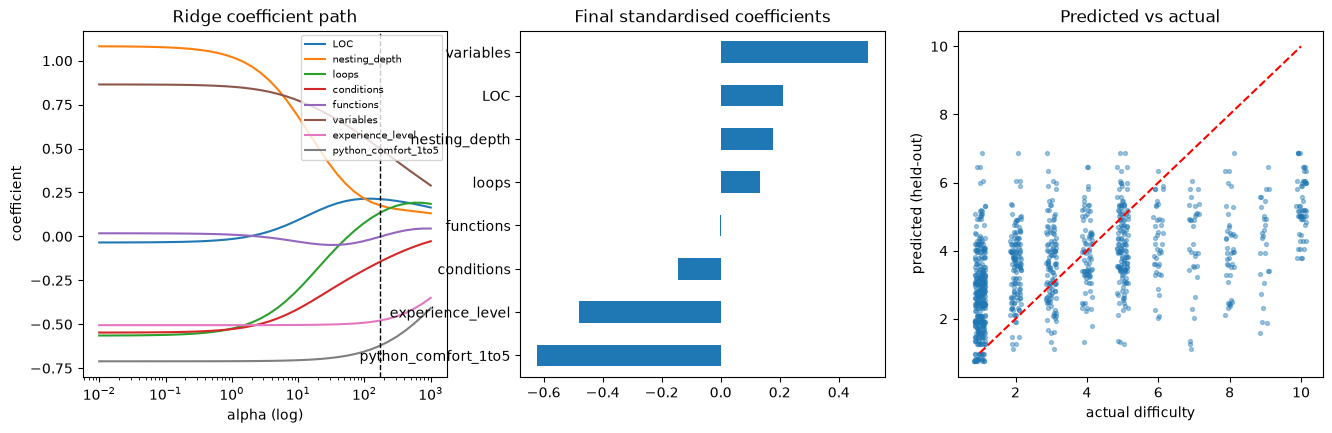

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
PATH = r"actual_cleaned_outlier_removed.csv"
df = pd.read_csv(PATH)

# ------------------------------------------------------------------
# 2. Choose variables
# ------------------------------------------------------------------
# cyclomatic_complexity == loops + conditions + 1 exactly, so it is dropped
# (perfect collinearity). Keep the other 6 code features.
code_features = ["LOC", "nesting_depth", "loops", "conditions",
                 "functions", "variables"]
person_features = ["experience_level", "python_comfort_1to5"]
features = code_features + person_features

X = df[features]
y = df["difficulty_1to10"]
groups = df["snippet_id"]   # same person rated 25 snippets

# ------------------------------------------------------------------
# 3. Pipeline: scale -> ridge
#    Scaling is inside the pipeline so it is re-fitted on the training
#    part of every fold (no leakage), and so the penalty treats all
#    features equally regardless of their units.
# ------------------------------------------------------------------
pipe = make_pipeline(StandardScaler(), Ridge())
alphas = np.logspace(-2, 3, 40)

# ------------------------------------------------------------------
# 4. Nested, participant-grouped cross-validation
#    Outer loop: honest performance estimate.
#    Inner loop: picks alpha using only the training participants.
# ------------------------------------------------------------------
outer = GroupKFold(n_splits=5)
inner = GroupKFold(n_splits=4)

search = GridSearchCV(
    pipe,
    param_grid={"ridge__alpha": alphas},
    cv=inner,
    scoring="neg_mean_squared_error",
)

# GridSearchCV must be told the groups for the inner split
pred = np.zeros(len(df))
chosen_alphas = []
for train_idx, test_idx in outer.split(X, y, groups):
    search.fit(X.iloc[train_idx], y.iloc[train_idx],
               groups=groups.iloc[train_idx])
    chosen_alphas.append(search.best_params_["ridge__alpha"])
    pred[test_idx] = search.predict(X.iloc[test_idx])

print("Held-out performance (outer 5-fold, grouped by participant)")

# Existing metrics
print(f"  R2       : {r2_score(y, pred):.3f}")
print(f"  RMSE     : {np.sqrt(mean_squared_error(y, pred)):.3f}")
print(f"  MAE      : {mean_absolute_error(y, pred):.3f}")

# NEW: Spearman's rank correlation coefficient
rho, p_value = spearmanr(y, pred)
print(f"  Spearman's rho : {rho:.3f}")
print(f"  Spearman p-value: {p_value:.4f}")

print(f"  alpha chosen per fold: {np.round(chosen_alphas, 2)}")

# ------------------------------------------------------------------
# 5. Final model on all data, using alpha tuned on all data
# ------------------------------------------------------------------
search.fit(X, y, groups=groups)
best_alpha = search.best_params_["ridge__alpha"]
final = search.best_estimator_
print(f"\nFinal alpha (all data): {best_alpha:.3f}")

coefs = pd.Series(final.named_steps["ridge"].coef_, index=features)
print("\nStandardised coefficients (difficulty points per +1 SD):")
print(coefs.sort_values(key=abs, ascending=False).round(3))
print(f"Intercept: {final.named_steps['ridge'].intercept_:.3f}")

# ------------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) coefficient path: how coefficients shrink as alpha grows
sc = StandardScaler().fit(X)
Xs = sc.transform(X)
path = np.array([Ridge(alpha=a).fit(Xs, y).coef_ for a in alphas])
for i, name in enumerate(features):
    ax[0].plot(alphas, path[:, i], label=name)
ax[0].set_xscale("log")
ax[0].axvline(best_alpha, color="k", ls="--", lw=1)
ax[0].set_xlabel("alpha (log)")
ax[0].set_ylabel("coefficient")
ax[0].set_title("Ridge coefficient path")
ax[0].legend(fontsize=7)

# (b) coefficient bar chart
coefs.sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Final standardised coefficients")

# (c) predicted vs actual (held-out)
ax[2].scatter(y + np.random.uniform(-.15, .15, len(y)), pred, s=8, alpha=.4)
ax[2].plot([1, 10], [1, 10], "r--")
ax[2].set_xlabel("actual difficulty")
ax[2].set_ylabel("predicted (held-out)")
ax[2].set_title("Predicted vs actual")


plt.show()



Held-out performance (outer 5-fold, grouped by participant)
  R2       : 0.246
  RMSE     : 2.370
  MAE      : 1.847
  Spearman's rho : 0.531
  Spearman p-value: 0.0000
  alpha chosen per fold: [0. 0. 0. 0. 0.]

Final alpha (all data): 0.0012

Standardised coefficients (difficulty points per +1 SD):
nesting_depth          0.973
variables              0.844
python_comfort_1to5   -0.710
conditions            -0.513
experience_level      -0.504
loops                 -0.495
functions              0.001
LOC                   -0.000
dtype: float64
Intercept: 3.501

Kept    (7): ['nesting_depth', 'loops', 'conditions', 'functions', 'variables', 'experience_level', 'python_comfort_1to5']
Dropped (1): ['LOC']


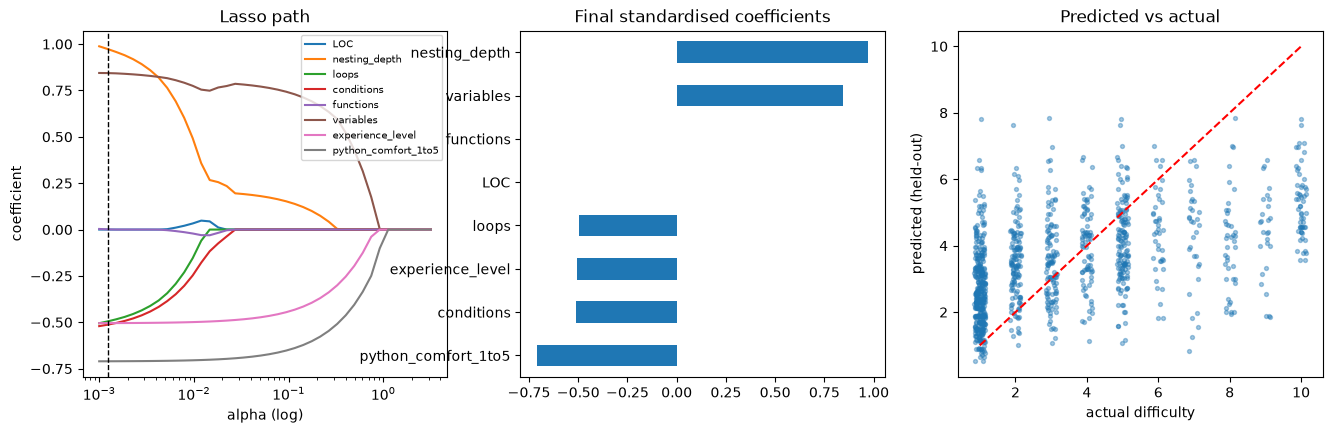

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

np.random.seed(42)

# ------------------------------------------------------------------
# 1. Load data  (CHANGE THIS to your own path)
# ------------------------------------------------------------------
PATH = r"actual_cleaned_outlier_removed.csv"
df = pd.read_csv(PATH)

# ------------------------------------------------------------------
# 2. Choose variables (same as ridge so results are comparable)
# ------------------------------------------------------------------
code_features = ["LOC", "nesting_depth", "loops", "conditions",
                 "functions", "variables"]
person_features = ["experience_level", "python_comfort_1to5"]
features = code_features + person_features

X = df[features]
y = df["difficulty_1to10"]
groups = df["participant_code"]

# ------------------------------------------------------------------
# 3. Pipeline: scale -> lasso
#    Lasso penalty: alpha * sum(|beta|). Unlike ridge, it can shrink
#    coefficients exactly to zero, so it also does feature selection.
#    The alpha grid is smaller than for ridge because the L1 penalty
#    zeroes coefficients at much lower alpha values.
# ------------------------------------------------------------------
pipe = make_pipeline(StandardScaler(), Lasso(max_iter=50000))
alphas = np.logspace(-3, 0.5, 40)

# ------------------------------------------------------------------
# 4. Nested, participant-grouped cross-validation
# ------------------------------------------------------------------
outer = GroupKFold(n_splits=5)
inner = GroupKFold(n_splits=4)

search = GridSearchCV(
    pipe,
    param_grid={"lasso__alpha": alphas},
    cv=inner,
    scoring="neg_mean_squared_error",
)

pred = np.zeros(len(df))
chosen_alphas = []
for train_idx, test_idx in outer.split(X, y, groups):
    search.fit(X.iloc[train_idx], y.iloc[train_idx],
               groups=groups.iloc[train_idx])
    chosen_alphas.append(search.best_params_["lasso__alpha"])
    pred[test_idx] = search.predict(X.iloc[test_idx])

print("Held-out performance (outer 5-fold, grouped by participant)")

# Existing metrics
print(f"  R2       : {r2_score(y, pred):.3f}")
print(f"  RMSE     : {np.sqrt(mean_squared_error(y, pred)):.3f}")
print(f"  MAE      : {mean_absolute_error(y, pred):.3f}")

# NEW: Spearman's rank correlation coefficient
rho, p_value = spearmanr(y, pred)
print(f"  Spearman's rho : {rho:.3f}")
print(f"  Spearman p-value: {p_value:.4f}")

print(f"  alpha chosen per fold: {np.round(chosen_alphas, 2)}")

# ------------------------------------------------------------------
# 5. Final model on all data
# ------------------------------------------------------------------
search.fit(X, y, groups=groups)
best_alpha = search.best_params_["lasso__alpha"]
final = search.best_estimator_
print(f"\nFinal alpha (all data): {best_alpha:.4f}")

coefs = pd.Series(final.named_steps["lasso"].coef_, index=features)
print("\nStandardised coefficients (difficulty points per +1 SD):")
print(coefs.sort_values(key=abs, ascending=False).round(3))
print(f"Intercept: {final.named_steps['lasso'].intercept_:.3f}")

kept = coefs[coefs != 0].index.tolist()
dropped = coefs[coefs == 0].index.tolist()
print(f"\nKept    ({len(kept)}): {kept}")
print(f"Dropped ({len(dropped)}): {dropped}")

# ------------------------------------------------------------------
# 6. Plots
# ------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) lasso path: coefficients hit exactly zero as alpha grows
Xs = StandardScaler().fit_transform(X)
path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs, y).coef_
                 for a in alphas])
for i, name in enumerate(features):
    ax[0].plot(alphas, path[:, i], label=name)
ax[0].set_xscale("log")
ax[0].axvline(best_alpha, color="k", ls="--", lw=1)
ax[0].set_xlabel("alpha (log)")
ax[0].set_ylabel("coefficient")
ax[0].set_title("Lasso path")
ax[0].legend(fontsize=7)

# (b) coefficient bar chart
coefs.sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Final standardised coefficients")

# (c) predicted vs actual (held-out)
ax[2].scatter(y + np.random.uniform(-.15, .15, len(y)), pred, s=8, alpha=.4)
ax[2].plot([1, 10], [1, 10], "r--")
ax[2].set_xlabel("actual difficulty")
ax[2].set_ylabel("predicted (held-out)")
ax[2].set_title("Predicted vs actual")


plt.show()
